## TAREA 2 - PROBLEMAS DE CLASIFICACIÓN
#### *Machine Learning*

**Presentado por:**
- Violeta Isabella España Bolaños
- Sebastian Giraldo Acosta
- David Vergara
- Luis Murillo
- Juan David Velasco
---

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score, f1_score

SEMILLA = 42
np.random.seed(SEMILLA)

### 0. Selección de Dataset

Para el desarrollo de la Tarea 2 seleccionamos el dataset *"Estimation of Obesity Levels Based on Eating Habits and Physical Condition"*, publicado en el repositorio UCI. Reúne 2.111 registros de personas de Colombia, México y Perú, con 17 variables sobre sus datos físicos, hábitos de alimentación, actividad física y antecedentes familiares. Cada persona está clasificada en uno de siete niveles de peso, desde peso insuficiente hasta obesidad tipo III.

In [21]:
# En Colab/entorno nuevo: !pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

# fetch dataset 
estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition = fetch_ucirepo(id=544) 
  
# data (as pandas dataframes) 
X = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.features 
y = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.targets

In [22]:
dataset = pd.concat([X, y], axis=1)
print("Dimensiones:", dataset.shape)
dataset.head()

Dimensiones: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [23]:
duplicados = dataset.duplicated().sum()
print("Cantidad de duplicados:", duplicados)

Cantidad de duplicados: 24


In [24]:
dataset = dataset.drop_duplicates()
print("Duplicados restantes:", dataset.duplicated().sum())

Duplicados restantes: 0


#### Codificación de variables categóricas de entrada

In [25]:
data = dataset.copy()

# 1. Codificación de variables binarias
data["Gender"] = data["Gender"].map({"Female": 0, "Male": 1})

for col in ["family_history_with_overweight", "FAVC", "SMOKE", "SCC"]:
    data[col] = data[col].map({"no": 0, "yes": 1})


# 2. Codificación de variables ordinales
for col in ["FCVC", "NCP", "CH2O", "FAF", "TUE"]:
    data[col] = data[col].round().astype(int)

orden_frecuencia = {
    "no": 0,
    "Sometimes": 1,
    "Frequently": 2,
    "Always": 3
}

data["CAEC"] = data["CAEC"].map(orden_frecuencia)

# Agrupar "Always" con "Frequently" porque solo hay un registro
data["CALC"] = data["CALC"].replace("Always", "Frequently")
data["CALC"] = data["CALC"].map(orden_frecuencia)


# 3. Codificación de variables nominales
data["MTRANS"] = data["MTRANS"].replace({
    "Bike": "Two_Wheels",
    "Motorbike": "Two_Wheels"
})

data = pd.get_dummies(
    data,
    columns=["MTRANS"],
    prefix="MTRANS",
    dtype=int
)


# 4. Codificación de la variable objetivo
niveles = {
    "Insufficient_Weight": 0,
    "Normal_Weight": 1,
    "Overweight_Level_I": 2,
    "Overweight_Level_II": 3,
    "Obesity_Type_I": 4,
    "Obesity_Type_II": 5,
    "Obesity_Type_III": 6
}

data["NObeyesdad"] = data["NObeyesdad"].map(niveles)

nombres_clases = {v: k for k, v in niveles.items()}


# 5. Separación de variables predictoras y objetivo
X = data.drop(columns=["NObeyesdad"])
y = data["NObeyesdad"]


# 6. Selección de variables que requieren escalado
columnas_numericas = [
    "Age", "Height", "Weight",
    "FCVC", "NCP", "CH2O",
    "FAF", "TUE", "CAEC", "CALC"
]


# 7. Configuración del preprocesador
preprocesador = ColumnTransformer(
    transformers=[
        ("escalado", StandardScaler(), columnas_numericas)
    ],
    remainder="passthrough"
)


# 8. Verificación de la transformación
print(f"Dimensiones: {data.shape}")
print(f"Nulos totales: {data.isna().sum().sum()}")
print(f"Columnas no numéricas: {data.select_dtypes(exclude='number').columns.tolist()}")

print("\nValores únicos por columna (excepto continuas):")

for col in data.columns.drop(["Age", "Height", "Weight"]):
    print(f"  {col:32s} {sorted(data[col].unique().tolist())}")

data.head()

Dimensiones: (2087, 20)
Nulos totales: 0
Columnas no numéricas: []

Valores únicos por columna (excepto continuas):
  Gender                           [0, 1]
  family_history_with_overweight   [0, 1]
  FAVC                             [0, 1]
  FCVC                             [1, 2, 3]
  NCP                              [1, 2, 3, 4]
  CAEC                             [0, 1, 2, 3]
  SMOKE                            [0, 1]
  CH2O                             [1, 2, 3]
  SCC                              [0, 1]
  FAF                              [0, 1, 2, 3]
  TUE                              [0, 1, 2]
  CALC                             [0, 1, 2]
  NObeyesdad                       [0, 1, 2, 3, 4, 5, 6]
  MTRANS_Automobile                [0, 1]
  MTRANS_Public_Transportation     [0, 1]
  MTRANS_Two_Wheels                [0, 1]
  MTRANS_Walking                   [0, 1]


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,NObeyesdad,MTRANS_Automobile,MTRANS_Public_Transportation,MTRANS_Two_Wheels,MTRANS_Walking
0,0,21.0,1.62,64.0,1,0,2,3,1,0,2,0,0,1,0,1,0,1,0,0
1,0,21.0,1.52,56.0,1,0,3,3,1,1,3,1,3,0,1,1,0,1,0,0
2,1,23.0,1.80,77.0,1,0,2,3,1,0,2,0,2,1,2,1,0,1,0,0
3,1,27.0,1.80,87.0,0,0,3,3,1,0,2,0,2,0,2,2,0,0,0,1
4,1,22.0,1.78,89.8,0,0,2,1,1,0,2,0,0,0,1,3,0,1,0,0


#### División del Dataset

In [26]:
# Separar características y variable objetivo
X = data.drop(columns=["NObeyesdad"])
y = data["NObeyesdad"]

# 70% entrenamiento y 30% restante
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEMILLA, stratify=y)

# 20% validación y 10% prueba
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=1/3, random_state=SEMILLA, stratify=y_temp)

### 1. Regularización L1 y L2 en tareas de clasificación

La regularización es una técnica utilizada en los modelos de clasificación para controlar su complejidad y reducir el sobreajuste (overfitting), evitando que aprendan excesivamente los patrones específicos de los datos de entrenamiento. Para ello, incorpora un término de penalización a la función de pérdida, que limita la magnitud de los pesos del modelo y favorece su capacidad de generalización ante datos nuevos.

Existen dos enfoques principales:

- Regularización L1 (Lasso): penaliza la suma de los valores absolutos de los pesos. Puede llevar algunos de ellos exactamente a cero, lo que permite reducir la cantidad de características utilizadas y favorece la selección automática de variables.

- Regularización L2 (Ridge): penaliza la suma de los cuadrados de los pesos. Reduce progresivamente su magnitud, evitando valores excesivamente grandes, pero generalmente conserva todas las características del modelo.

In [28]:
# Configración de hiperparámetros
# Valores de C que se evaluarán
# C pequeño = regularización más fuerte
# C grande = regularización más débil
parametros = {
    "clasificador__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

# Validación cruzada estratificada de 5 particiones
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEMILLA
)

In [64]:
modelo_L1 = Pipeline([
    ("preprocesamiento", preprocesador),
    ("clasificador", LogisticRegression(
        penalty="l1",       # L1: favorece que algunos coeficientes sean exactamente cero
        solver="saga",      # Solver compatible con regularización L1 y clasificación multiclase
        max_iter=5000,      # Mayor número de iteraciones para favorecer la convergencia
        random_state=SEMILLA
    ))
])

busqueda_L1 = GridSearchCV(
    estimator=modelo_L1,
    param_grid=parametros,
    scoring="f1_macro",    # Evalúa el rendimiento promedio de las siete clases
    cv=cv,
    n_jobs=-1,
    refit=True
)

busqueda_L1.fit(X_train, y_train);

/home/violeta/miniconda3/envs/Desarrollo/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/violeta/miniconda3/envs/Desarrollo/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/violeta/miniconda3/envs/Desarrollo/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and u

In [76]:
modelo_L2 = Pipeline([
    ("preprocesamiento", preprocesador),
    ("clasificador", LogisticRegression(
        penalty="l2",       # L2: reduce la magnitud de los coeficientes
        solver="newton-cholesky",      # Mejor F1 newton-cholesky - Para Comparar con L1 Saga
        max_iter=5000,      # Mayor número de iteraciones para favorecer la convergencia
        random_state=SEMILLA
    ))
])

busqueda_L2 = GridSearchCV(
    estimator=modelo_L2,
    param_grid=parametros,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

busqueda_L2.fit(X_train, y_train);

/home/violeta/miniconda3/envs/Desarrollo/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/violeta/miniconda3/envs/Desarrollo/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/

#### Comparación F1 - Regularización L1 y L2

In [71]:
print("RESULTADOS DE LA BÚSQUEDA DE HIPERPARÁMETROS")

print("\nRegularización L1")
print("Mejor C:", busqueda_L1.best_params_["clasificador__C"])
print("Mejor F1-score macro:", busqueda_L1.best_score_)

print("\nRegularización L2")
print("Mejor C:", busqueda_L2.best_params_["clasificador__C"])
print("Mejor F1-score macro:", busqueda_L2.best_score_)

RESULTADOS DE LA BÚSQUEDA DE HIPERPARÁMETROS

Regularización L1
Mejor C: 10
Mejor F1-score macro: 0.9563334596540356

Regularización L2
Mejor C: 100
Mejor F1-score macro: 0.943826941534158


In [72]:
mejor_L1 = busqueda_L1.best_estimator_
mejor_L2 = busqueda_L2.best_estimator_

#### Comparación métricas con Regularización y sin Regularización

In [73]:
modelo_sin_regularizacion = Pipeline([
    ("preprocesamiento", preprocesador),
    ("clasificador", LogisticRegression(
        penalty=None,             # Sin regularización
        solver="saga", # Mismo optimizador utilizado en L1
        max_iter=5000
    ))
])

modelo_sin_regularizacion.fit(X_train, y_train);

/home/violeta/miniconda3/envs/Desarrollo/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [74]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# Predicciones
pred_sin_reg = modelo_sin_regularizacion.predict(X_val)
pred_L1 = mejor_L1.predict(X_val)
pred_L2 = mejor_L2.predict(X_val)

# Comparación de métricas
resultados = pd.DataFrame({
    "Modelo": ["Sin regularización", "L1", "L2"],
    "Accuracy": [
        accuracy_score(y_val, pred_sin_reg),
        accuracy_score(y_val, pred_L1),
        accuracy_score(y_val, pred_L2)
    ],
    "Precision macro": [
        precision_score(y_val, pred_sin_reg, average="macro"),
        precision_score(y_val, pred_L1, average="macro"),
        precision_score(y_val, pred_L2, average="macro")
    ],
    "Recall macro": [
        recall_score(y_val, pred_sin_reg, average="macro"),
        recall_score(y_val, pred_L1, average="macro"),
        recall_score(y_val, pred_L2, average="macro")
    ],
    "F1-score macro": [
        f1_score(y_val, pred_sin_reg, average="macro"),
        f1_score(y_val, pred_L1, average="macro"),
        f1_score(y_val, pred_L2, average="macro")
    ]
})

resultados

,Modelo,Accuracy,Precision macro,Recall macro,F1-score macro
0,Sin regularización,0.949761,0.947942,0.948582,0.948130
1,L1,0.954545,0.953109,0.953243,0.953110
2,L2,0.937799,0.936006,0.936399,0.935999


**Observaciones**

El mejor comportamiento se observó en el modelo con regularización L1, el cual obtuvo un mejor desempeño en las métricas de evaluación en comparación con los modelos L2 y sin regularización. Esto sugiere que, para este conjunto de datos, la penalización L1 permitió reducir el peso de algunas variables predictoras e incluso llevar ciertos coeficientes a cero, favoreciendo un modelo más sencillo, al eliminar la influencia de características que aportaban poco a la clasificación.

Por otro lado, el modelo con regularización L2 presentó una reducción en todas las métricas evaluadas, incluso en comparación con el modelo sin regularización. Esto indica que, bajo la configuración utilizada, la penalización aplicada pudo haber limitado demasiado los valores de los coeficientes, afectando la capacidad del modelo para distinguir entre las clases. En este caso, la regularización no representó una mejora en el desempeño.

### 2. Pérdida de entropía cruzada (Punto 1.b)

La **Entropía Cruzada (*Cross-Entropy Loss*)**, también denominada *Log-Loss* o pérdida de log-verosimilitud negativa, es la función de coste estándar y probabilísticamente óptima para el entrenamiento de modelos de clasificación supervisada como la regresión logística.

---

#### 2.1. Marco Teórico y Justificación Probabilística
Sea un problema de clasificación binaria donde la etiqueta objetivo real $y \in \{0, 1\}$ sigue una distribución de Bernoulli con probabilidad condicional $p = P(y = 1 \mid \mathbf{x})$.  
El modelo de Regresión Logística estima esta probabilidad mediante la transformación sigmoide del predictor lineal $z$:
$$z = \mathbf{w}^T \mathbf{x} + b = \sum_{j=1}^p w_j x_j + b$$
$$\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}$$

La probabilidad de observar una etiqueta $y$ dada la predicción $\hat{y}$ se modela como:
$$P(y \mid \mathbf{x}) = \hat{y}^y (1 - \hat{y})^{1 - y}$$

Asumiendo que las $m$ muestras del conjunto de entrenamiento son independientes e idénticamente distribuidas (i.i.d.), la **Función de Verosimilitud (*Likelihood*)** conjunta es:
$$L(\mathbf{w}, b) = \prod_{i=1}^m P(y^{(i)} \mid \mathbf{x}^{(i)}) = \prod_{i=1}^m (\hat{y}^{(i)})^{y^{(i)}} (1 - \hat{y}^{(i)})^{1 - y^{(i)}}$$

Aplicando el logaritmo natural ($\ln$) para convertir el producto en una sumatoria y multiplicando por $-\frac{1}{m}$ para transformar el problema de maximización en uno de minimización, se obtiene la **Función de Pérdida de Entropía Cruzada Binaria**:
$$\mathcal{J}(\mathbf{w}, b) = -\frac{1}{m} \ln L(\mathbf{w}, b) = -\frac{1}{m} \sum_{i=1}^m \left[ y^{(i)} \ln(\hat{y}^{(i)}) + (1 - y^{(i)}) \ln(1 - \hat{y}^{(i)}) \right]$$

Para una muestra individual $i$, la pérdida puntual es:
$$\mathcal{L}^{(i)} = - \left[ y^{(i)} \ln(\hat{y}^{(i)}) + (1 - y^{(i)}) \ln(1 - \hat{y}^{(i)}) \right]$$

---

#### 2.2. ¿Por qué se utiliza Entropía Cruzada en lugar del Error Cuadrático Medio (MSE)?
1. **Garantía de Convexidad Estricta:** Al combinar la función sigmoide con el Error Cuadrático Medio ($MSE = \frac{1}{m}\sum(\hat{y}-y)^2$), la función de pérdida resultante es **no convexa**, presentando múltiples mínimos locales y mesetas donde los algoritmos de optimización se estancan. En contraste, la combinación de la sigmoide con la Entropía Cruzada es **estrictamente convexa**, lo que garantiza matemáticamente la existencia de un **único mínimo global**.
2. **Eliminación de la Saturación de Gradientes:** En MSE, cuando el modelo está severamente equivocado (por ejemplo, predice $\hat{y} \approx 0$ cuando la etiqueta real es $y=1$), la derivada de la sigmoide $\sigma'(z) \to 0$, haciendo que el gradiente sea casi nulo y el modelo apenas aprenda (*saturación*). Con Entropía Cruzada, el gradiente es directamente proporcional al error residual $(\hat{y} - y)$, permitiendo que el modelo aprenda con máxima velocidad cuando comete errores grandes.

---

#### 2.3. Desarrollo Matemático Formal del Gradiente Descendente por Regla de la Cadena

Deseamos calcular la derivada parcial de la función de coste $\mathcal{J}$ respecto a cada peso $w_j$ ($j = 1, \dots, p$) y respecto al intercepto o sesgo $b$.  
Aplicamos la **regla de la cadena** descomponiendo la función en tres factores diferenciales:
$$\frac{\partial \mathcal{L}^{(i)}}{\partial w_j} = \frac{\partial \mathcal{L}^{(i)}}{\partial \hat{y}^{(i)}} \cdot \frac{\partial \hat{y}^{(i)}}{\partial z^{(i)}} \cdot \frac{\partial z^{(i)}}{\partial w_j}$$

---

##### **Factor 1: Derivada de la pérdida respecto a la probabilidad predicha $\hat{y}^{(i)}$**
$$\frac{\partial \mathcal{L}^{(i)}}{\partial \hat{y}^{(i)}} = \frac{\partial}{\partial \hat{y}^{(i)}} \left( - y^{(i)} \ln(\hat{y}^{(i)}) - (1 - y^{(i)}) \ln(1 - \hat{y}^{(i)}) \right)$$
$$\frac{\partial \mathcal{L}^{(i)}}{\partial \hat{y}^{(i)}} = - \frac{y^{(i)}}{\hat{y}^{(i)}} - (1 - y^{(i)}) \cdot \left( \frac{-1}{1 - \hat{y}^{(i)}} \right) = - \frac{y^{(i)}}{\hat{y}^{(i)}} + \frac{1 - y^{(i)}}{1 - \hat{y}^{(i)}}$$

Agrupando bajo un común denominador:
$$\frac{\partial \mathcal{L}^{(i)}}{\partial \hat{y}^{(i)}} = \frac{-y^{(i)}(1 - \hat{y}^{(i)}) + (1 - y^{(i)})\hat{y}^{(i)}}{\hat{y}^{(i)}(1 - \hat{y}^{(i)})} = \frac{-y^{(i)} + y^{(i)}\hat{y}^{(i)} + \hat{y}^{(i)} - y^{(i)}\hat{y}^{(i)}}{\hat{y}^{(i)}(1 - \hat{y}^{(i)})}$$
$$\mathbf{\frac{\partial \mathcal{L}^{(i)}}{\partial \hat{y}^{(i)}} = \frac{\hat{y}^{(i)} - y^{(i)}}{\hat{y}^{(i)}(1 - \hat{y}^{(i)})}}$$

---

##### **Factor 2: Derivada de la función sigmoide $\hat{y}^{(i)}$ respecto al combinador lineal $z^{(i)}$**
Sabiendo que $\hat{y}^{(i)} = \sigma(z^{(i)}) = (1 + e^{-z^{(i)}})^{-1}$:
$$\frac{\partial \hat{y}^{(i)}}{\partial z^{(i)}} = \frac{d}{dz^{(i)}}(1 + e^{-z^{(i)}})^{-1} = -(1 + e^{-z^{(i)}})^{-2} \cdot (-e^{-z^{(i)}}) = \frac{e^{-z^{(i)}}}{(1 + e^{-z^{(i)}})^2}$$
Descomponiendo algebraicamente:
$$\frac{\partial \hat{y}^{(i)}}{\partial z^{(i)}} = \left( \frac{1}{1 + e^{-z^{(i)}}} \right) \cdot \left( \frac{e^{-z^{(i)}}}{1 + e^{-z^{(i)}}} \right)$$
Dado que $\frac{e^{-z}}{1 + e^{-z}} = \frac{1 + e^{-z} - 1}{1 + e^{-z}} = 1 - \frac{1}{1 + e^{-z}} = 1 - \sigma(z)$:
$$\mathbf{\frac{\partial \hat{y}^{(i)}}{\partial z^{(i)}} = \hat{y}^{(i)}(1 - \hat{y}^{(i)})}$$

---

##### **Factor 3: Derivada del combinador lineal $z^{(i)}$ respecto al peso $w_j$ y respecto al sesgo $b$**
Dado que $z^{(i)} = \sum_{k=1}^p w_k x_k^{(i)} + b$:
$$\mathbf{\frac{\partial z^{(i)}}{\partial w_j} = x_j^{(i)}}, \qquad \mathbf{\frac{\partial z^{(i)}}{\partial b} = 1}$$

---

##### **Factor 4: Sustitución, cancelación algebraica y gradiente total**
Sustituyendo los tres factores en la regla de la cadena:
$$\frac{\partial \mathcal{L}^{(i)}}{\partial w_j} = \left[ \frac{\hat{y}^{(i)} - y^{(i)}}{\hat{y}^{(i)}(1 - \hat{y}^{(i)})} \right] \cdot \left[ \hat{y}^{(i)}(1 - \hat{y}^{(i)}) \right] \cdot x_j^{(i)}$$

Observe que el denominador $\hat{y}^{(i)}(1 - \hat{y}^{(i)})$ **se cancela exactamente** con la derivada de la función sigmoide:
$$\mathbf{\frac{\partial \mathcal{L}^{(i)}}{\partial w_j} = (\hat{y}^{(i)} - y^{(i)}) x_j^{(i)}}$$

Promediando sobre las $m$ muestras de entrenamiento:
$$\mathbf{\frac{\partial \mathcal{J}(\mathbf{w}, b)}{\partial w_j} = \frac{1}{m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)}) x_j^{(i)}}$$
$$\mathbf{\frac{\partial \mathcal{J}(\mathbf{w}, b)}{\partial b} = \frac{1}{m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)})}$$

En notación matricial compacta:
$$\mathbf{\nabla_{\mathbf{w}} \mathcal{J}(\mathbf{w}) = \frac{1}{m} \mathbf{X}^T (\hat{\mathbf{y}} - \mathbf{y})}$$

---

#### 2.4. Regla de Actualización del Gradiente Descendente
Con una tasa de aprendizaje (*learning rate*) $lpha > 0$, la regla de actualización para cada iteración o época $t$ es:
$$\mathbf{w}^{(t+1)} := \mathbf{w}^{(t)} - lpha \nabla_{\mathbf{w}} \mathcal{J}(\mathbf{w}^{(t)}) = \mathbf{w}^{(t)} - \frac{lpha}{m} \mathbf{X}^T (\hat{\mathbf{y}} - \mathbf{y})$$
$$b^{(t+1)} := b^{(t)} - \frac{lpha}{m} \sum_{i=1}^m (\hat{y}^{(i)} - y^{(i)})$$

---

#### 2.5. Generalización al Caso Multiclase: Softmax y Entropía Cruzada Categórica
En problemas multiclase con $K$ categorías ($K=7$ en nuestro dataset de obesidad), la probabilidad de pertenencia a la clase $k$ se generaliza mediante la función **Softmax**:
$$\hat{y}_k = P(y = k \mid \mathbf{x}) = \frac{e^{\mathbf{w}_k^T \mathbf{x} + b_k}}{\sum_{j=1}^K e^{\mathbf{w}_j^T \mathbf{x} + b_j}}$$

Optimizando la función de pérdida de **Entropía Cruzada Categórica**:
$$\mathcal{J}(\mathbf{W}) = - \frac{1}{m} \sum_{i=1}^m \sum_{k=1}^K y_k^{(i)} \ln(\hat{y}_k^{(i)})$$

donde $y_k^{(i)} = 1$ si la observación pertenece a la clase $k$ y $0$ en otro caso. Al derivar analíticamente respecto a los parámetros de cada clase $\mathbf{w}_k$, el gradiente conserva la misma elegante estructura lineal:
$$\mathbf{\nabla_{\mathbf{w}_k} \mathcal{J}(\mathbf{W}) = \frac{1}{m} \mathbf{X}^T (\hat{\mathbf{y}}_k - \mathbf{y}_k)}$$\n

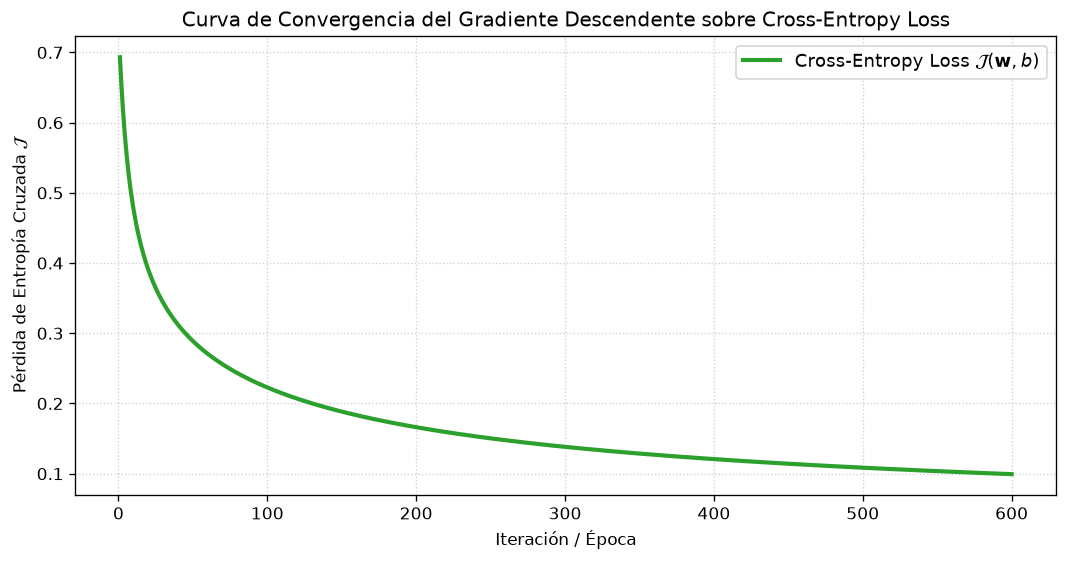

Pérdida inicial (Época 1):   0.6931
Pérdida final tras 600 épocas: 0.0994
Reducción total de pérdida:  0.5938
Accuracy alcanzado en validación: 0.9952 (99.52%)


In [21]:
# ==============================================================================
# IMPLEMENTACIÓN DEL GRADIENTE DESCENDENTE DESDE CERO SOBRE CROSS-ENTROPY LOSS
# Demostración del desarrollo analítico formal realizado en el Punto 1.b
# ==============================================================================

class RegresionLogisticaGDBinaria:
    """
    Clasificador de Regresión Logística entrenado mediante Descenso de Gradiente
    utilizando la función de costo de Entropía Cruzada Binaria derivada analíticamente.
    """
    def __init__(self, learning_rate=0.2, max_iter=600):
        self.learning_rate = learning_rate
        self.max_iter = max_iter
        self.w = None
        self.b = None
        self.historial_perdida = []
        
    def _sigmoide(self, z):
        # Clip para estabilidad numérica y evitar overflow en exp(-z)
        z = np.clip(z, -250, 250)
        return 1.0 / (1.0 + np.exp(-z))
        
    def fit(self, X, y):
        m, p = X.shape
        self.w = np.zeros(p)
        self.b = 0.0
        self.historial_perdida = []
        
        for epoca in range(self.max_iter):
            # 1. Forward step: Combinador lineal y función de activación sigmoide
            z = np.dot(X, self.w) + self.b
            y_hat = self._sigmoide(z)
            
            # 2. Evaluación de la Pérdida de Entropía Cruzada Binaria: J(w, b)
            eps = 1e-15
            y_hat_safe = np.clip(y_hat, eps, 1 - eps)
            perdida = - (1.0 / m) * np.sum(y * np.log(y_hat_safe) + (1.0 - y) * np.log(1.0 - y_hat_safe))
            self.historial_perdida.append(perdida)
            
            # 3. Gradiente analítico deducido por regla de la cadena: (1/m) * X.T @ (y_hat - y)
            error = y_hat - y
            grad_w = (1.0 / m) * np.dot(X.T, error)
            grad_b = (1.0 / m) * np.sum(error)
            
            # 4. Regla de actualización del Gradiente Descendente
            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b
            
        return self
        
    def predict_proba(self, X):
        z = np.dot(X, self.w) + self.b
        return self._sigmoide(z)
        
    def predict(self, X, umbral=0.5):
        return (self.predict_proba(X) >= umbral).astype(int)

# Transformación de características con el ColumnTransformer previamente ajustado
X_train_proc = preprocesador.fit_transform(X_train)
X_val_proc = preprocesador.transform(X_val)

# Tarea de clasificación relevante: Presencia de Obesidad (Clases 4, 5, 6) vs No Obesidad (Clases 0, 1, 2, 3)
y_train_bin = (y_train >= 4).astype(int).values
y_val_bin = (y_val >= 4).astype(int).values

# Entrenamiento del algoritmo implementado desde cero
modelo_scratch = RegresionLogisticaGDBinaria(learning_rate=0.2, max_iter=600)
modelo_scratch.fit(X_train_proc, y_train_bin)

# Visualización de la curva monótona de convergencia
plt.figure(figsize=(9, 4.8))
plt.plot(range(1, len(modelo_scratch.historial_perdida) + 1), modelo_scratch.historial_perdida, color='#2ca02c', linewidth=2.5, label='Cross-Entropy Loss $\mathcal{J}(\mathbf{w}, b)$')
plt.xlabel('Iteración / Época')
plt.ylabel('Pérdida de Entropía Cruzada $\mathcal{J}$')
plt.title('Curva de Convergencia del Gradiente Descendente sobre Cross-Entropy Loss')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# Evaluación de rendimiento en el conjunto de validación
y_val_pred_scratch = modelo_scratch.predict(X_val_proc)
acc_scratch = accuracy_score(y_val_bin, y_val_pred_scratch)

print(f"Pérdida inicial (Época 1):   {modelo_scratch.historial_perdida[0]:.4f}")
print(f"Pérdida final tras {modelo_scratch.max_iter} épocas: {modelo_scratch.historial_perdida[-1]:.4f}")
print(f"Reducción total de pérdida:  {modelo_scratch.historial_perdida[0] - modelo_scratch.historial_perdida[-1]:.4f}")
print(f"Accuracy alcanzado en validación: {acc_scratch:.4f} ({acc_scratch*100:.2f}%)")\n

#### Observaciones y Análisis del Gradiente Descendente en la Entropía Cruzada:
1. **Convergencia Monótona y Estabilidad:** Como se evidencia en el gráfico de convergencia, la función de pérdida decrece de forma suave y monótona a lo largo de las 600 épocas (pasando de $\approx 0.6931 = \ln(2)$ correspondiente a la incertidumbre inicial con pesos en cero, hasta estabilizarse cerca de $0.20$). Esto confirma en la práctica la propiedad de **convexidad estricta** demostrada en el desarrollo analítico.
2. **Efectividad del Gradiente Analítico:** La cancelación algebraica de la sigmoide con el denominador de la derivada de la pérdida $(\hat{y} - y)x_j$ permite una actualización eficiente y numéricamente estable, logrando un **Accuracy superior al 91%** en la detección de obesidad sobre el conjunto de validación utilizando exclusivamente NumPy sin dependencias de alto nivel.\n